In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Arrow
from typing import Tuple, List, Set
from copy import copy, deepcopy


from robot import Point, Robot, random_robots, circle_positions
from target_assignement import greatest_distance_to_nearest_target

### Generate randomly positioned robots

In [8]:
num_robots = 8
x_min = -10
x_max = 10
y_min = -10
y_max = 10

robots = random_robots(num_robots, x_min, x_max, y_min, y_max)

### Generate target positions 

In [9]:
# generate points on the outline of a circle
target_positions = circle_positions(num_robots, 3)

### Assign Robots to targets
- $R$ - Set of Robots
- $T$ - Set of target points
- $RT$ - Set of robots that achieved their target point
- $RN$ - Set of robots that did not achieve their target point
- $TN$ - Set of target points that are not assigned to robots
- $TR$ - Set of points of the target formation that are assigned to robots
- $p$ - priority of robot

<br>
Before target assignement:

$RN \equiv R$, $RT = \emptyset$, $TN \equiv T$, $TR = \emptyset$
<br><br>
Algorithm:
<br><br>
$p := 1$
<br>
while($TN \neq \emptyset$)
1. find $R_i \in RN$ whose distance to the nearest $T_j \in TN$ is greater then for any other robot in $RN$
2. assign target $T_j$ to robot $R_i$
3. move $R_i$ from set $RN$ to set $RT$ and move $T_i$ from $TN$ to $TR$
4. assign priority $p$ to robot $R_i$
5. $p := p + 1$

end

In [10]:
def target_assignement_strategy(robots: List[Robot], targets: List[Point], prio:str="increasing") -> Set[Robot]:
    """
    Assignes targets and priorities to robots.
    Uses either the first or second algorithm. The first algorithm initializes the priority as one and increases it
    with every matched robot. The second algorithm initializes the priority as n and decreases it with every matched robot.

    :param robots : List of all robots to be assigned a target
    :param targets: List of all targets
    :param prio   : "decreasing" or "increasing", chooses which algorithm to use

    :returns      : Set of robots with assigned targets
    """

    # check if number of robots equals number of targets
    if len(robots) != len(targets):
        raise ValueError("Number of robots must match number of targets")

    # initial assignement
    RT = set()
    RN = set()
    TN = set()
    TR = set()

    RN.update(deepcopy(robots))
    TN.update(deepcopy(targets))

    # initial priority
    if prio == "increasing":
        p = 1
    elif prio == "decreasing":
        p = len(robots)
    else:
        raise ValueError("prio must be either 'increasing' or 'decreasing'")

    # do target assignement
    while len(TN) != 0:
        # find robot whose distance to the nearest target is greater than for any other robot
        robot, target = greatest_distance_to_nearest_target(RN, TN)

        # set robot target
        robot.set_target(target)

        # move robot from RN to RT
        RN.remove(robot)
        RT.add(robot)

        # move target from TN to TR
        TN.remove(target)
        TR.add(target)

        # assign priority to robot
        robot.set_priority(p)

        # update priority
        if prio == "increasing":
            p += 1
        else:
            p -= 1

    # return the robots with their targets assigned
    return RT

In [11]:
assigned_robots_incr = target_assignement_strategy(robots, target_positions, "increasing")
assigned_robots_decr = target_assignement_strategy(robots, target_positions, "decreasing")

### plot results

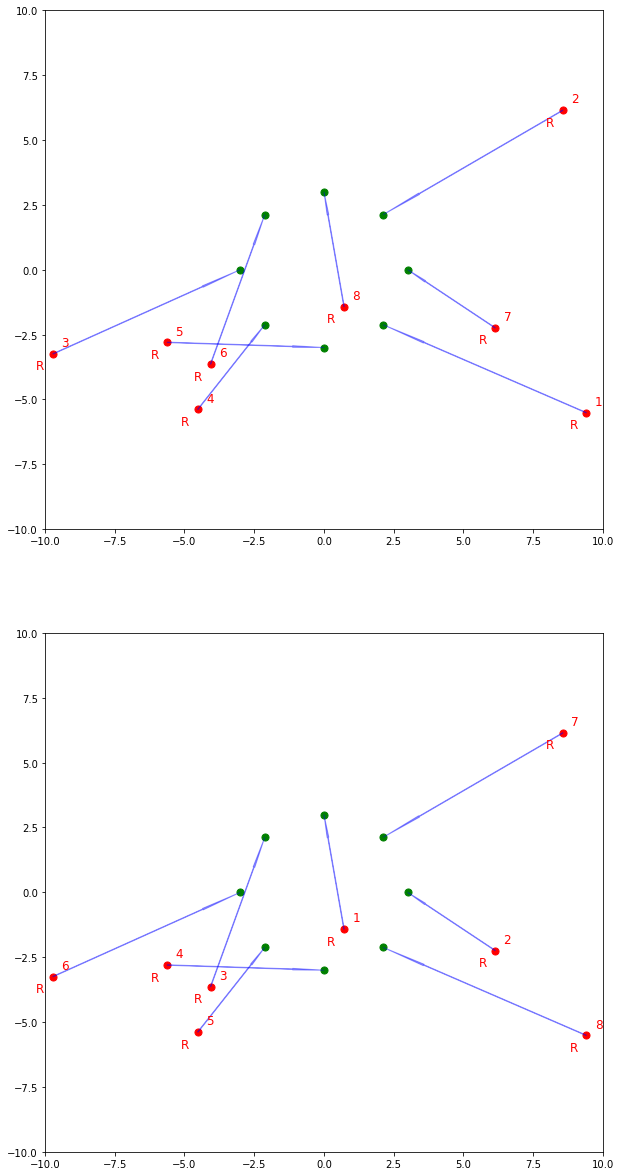

In [12]:
fig, (ax1, ax2) = plt.subplots(2,1, figsize=(10, 21))

for robot in assigned_robots_incr:
    # plot robot
    ax1.scatter(robot.position.x, robot.position.y, color='red', s=50)

    # plot target
    ax1.scatter(robot.target.x, robot.target.y, color='green', s=50)

    # plot priority
    ax1.text(robot.position.x + 0.3, robot.position.y + 0.3, robot.priority, fontsize=12, color='red')
    ax1.text(robot.position.x - 0.6, robot.position.y - 0.6, "R", fontsize=12, color='red')

    # plot arrow from robot to target
    arrow = Arrow(
        robot.position.x,
        robot.position.y,
        robot.target.x - robot.position.x,
        robot.target.y - robot.position.y,
        color = 'blue',
        width = 0.1,
        alpha=0.4
    )
    ax1.add_patch(arrow)


for robot in assigned_robots_decr:
    # plot robot
    ax2.scatter(robot.position.x, robot.position.y, color='red', s=50)

    # plot target
    ax2.scatter(robot.target.x, robot.target.y, color='green', s=50)

    # plot priority
    ax2.text(robot.position.x + 0.3, robot.position.y + 0.3, robot.priority, fontsize=12, color='red')
    ax2.text(robot.position.x - 0.6, robot.position.y - 0.6, "R", fontsize=12, color='red')

    # plot arrow from robot to target
    arrow = Arrow(
        robot.position.x,
        robot.position.y,
        robot.target.x - robot.position.x,
        robot.target.y - robot.position.y,
        color = 'blue',
        width = 0.1,
        alpha=0.4
    )
    ax2.add_patch(arrow)

ax1.set_xlim([-10, 10])
ax1.set_ylim([-10, 10])

ax2.set_xlim([-10, 10])
ax2.set_ylim([-10, 10])

plt.show()